# SafeDrive — Notebook 3: AutoML, Featuretools, Governance and Risk Comparison

This notebook extends the Stage 2 baseline with Featuretools deep feature synthesis (DFS), correlation-based filtering performed on training rows only, a tuned decision tree, a separate MLflow experiment, model versioning, Evidently, SHAP, risk bands and business KPIs. The held-out test rows remain unchanged.

## 1. Imports and load Stage 1 data

In [89]:
from pathlib import Path
import json, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

NOTEBOOK_DIR = Path.cwd()

# Find the folder containing the uploaded Stage 1 files
CANDIDATE_DIRS = [
    Path("/content"),
    Path("/content/outputs/stage1"),
    Path("/mnt/data/SafeDrive_Capstone/outputs/stage1"),
    NOTEBOOK_DIR,
    NOTEBOOK_DIR.parent / "outputs" / "stage1",
]

STAGE1_DIR = next(
    (p for p in CANDIDATE_DIRS
     if (p / "cleaned_modeling_data.csv").exists()
     and (p / "stage1_feature_manifest.json").exists()),
    None
)

if STAGE1_DIR is None:
    raise FileNotFoundError(
        "Stage 1 files not found. Please upload cleaned_modeling_data.csv "
        "and stage1_feature_manifest.json to /content."
    )

# Keep Stage 2 and Stage 3 outputs together with the existing project
PROJECT_DIR = Path("/content")
STAGE2_DIR = PROJECT_DIR / "outputs" / "stage2"
OUT_DIR = PROJECT_DIR / "outputs" / "stage3"
OUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(STAGE1_DIR / "cleaned_modeling_data.csv")
manifest = json.loads((STAGE1_DIR / "stage1_feature_manifest.json").read_text())

base_features = manifest["final_modeling_features"]
target = "is_claim"
X = df[base_features].copy()
y = df[target].astype(int).copy()
policy_ids = df["policy_id"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

train_indices, test_indices = X_train.index.copy(), X_test.index.copy()

print("Stage 1 files:", STAGE1_DIR)
print("Base features:", len(base_features), "| train:", X_train.shape, "| test:", X_test.shape)
print("Stage 3 output folder:", OUT_DIR)

Stage 1 files: /content
Base features: 30 | train: (46873, 30) | test: (11719, 30)
Stage 3 output folder: /content/outputs/stage3


## 2. Featuretools deep feature synthesis
Featuretools automatically generates simple mathematical combinations. The target is never included in the EntitySet. The transformation is row-wise; correlation filtering below uses only training labels.

In [90]:
%pip install -q featuretools
print("featuretools installed successfully")

featuretools installed successfully


In [91]:
try:
    import featuretools as ft
    featuretools_available = True
except ImportError:
    featuretools_available = False

df_fe = df.copy()
featuretools_features = []
candidate_feature_names = []
if featuretools_available:
    numeric_base_features = [
        c for c in base_features
        if c in df_fe.select_dtypes(include=np.number).columns
    ]
    dfs_input = df_fe[numeric_base_features].copy()
    dfs_input = dfs_input.reset_index().rename(columns={"index": "row_id"})
    entity_set = ft.EntitySet(id="safedrive_policies")
    entity_set = entity_set.add_dataframe(
        dataframe_name="policies", dataframe=dfs_input, index="row_id"
    )
    feature_matrix, feature_defs = ft.dfs(
        entityset=entity_set,
        target_dataframe_name="policies",
        trans_primitives=["multiply_numeric", "add_numeric"],
        max_depth=1,
        verbose=True
    )
    candidate_feature_names = [
        c for c in feature_matrix.columns
        if c not in ["row_id"] + numeric_base_features
    ]
    print("Total generated matrix columns:", len(feature_matrix.columns))
    print("Candidate DFS features:", len(candidate_feature_names))
    print(candidate_feature_names[:50])

Built 484 features
Elapsed: 00:03 | Progress: 100%|██████████
Total generated matrix columns: 484
Candidate DFS features: 462
['High_Risk_Driver_Flag + is_adjustable_steering', 'High_Risk_Driver_Flag + is_day_night_rear_view_mirror', 'High_Risk_Driver_Flag + is_parking_camera', 'High_Risk_Driver_Flag + is_parking_sensors', 'High_Risk_Driver_Flag + is_power_door_locks', 'High_Risk_Driver_Flag + is_power_steering', 'High_Risk_Driver_Flag + is_speed_alert', 'High_Risk_Driver_Flag + is_tpms', 'High_Risk_Driver_Flag + make', 'High_Risk_Driver_Flag + ncap_rating', 'High_Risk_Driver_Flag + policy_tenure', 'High_Risk_Driver_Flag + population_density', 'High_Risk_Driver_Flag + power_to_weight_ratio', 'High_Risk_Driver_Flag + torque_rpm', 'High_Risk_Driver_Flag + turning_radius', 'age_of_car + High_Risk_Driver_Flag', 'age_of_car + age_of_policyholder', 'age_of_car + airbags', 'age_of_car + displacement', 'age_of_car + gross_weight', 'age_of_car + height', 'age_of_car + is_adjustable_steering', '

## 3. Correlation-based feature filtering
The rubric's rule retains a generated feature only when its absolute target correlation exceeds the best absolute correlation among base numeric predictors. Infinite and missing generated values are replaced with zero for correlation calculation. This target-dependent filter is fitted on training rows only.

In [92]:
if featuretools_available:
    y_train_aligned = y_train.loc[train_indices]
    base_numeric = [
        c for c in base_features
        if c in X_train.select_dtypes(include=np.number).columns
    ]
    base_corr_values = X_train[base_numeric].corrwith(y_train).abs().dropna()
    best_base_corr = float(base_corr_values.max()) if not base_corr_values.empty else 0.0
    print("Best absolute base-feature correlation:", best_base_corr)

    retained_names = []
    for column in candidate_feature_names:
        values = feature_matrix.loc[train_indices, column].replace([np.inf, -np.inf], np.nan).fillna(0)
        correlation = values.corr(y_train_aligned)
        if pd.notna(correlation) and abs(correlation) > best_base_corr:
            retained_names.append(column)
    featuretools_features = retained_names
    print("Retained Featuretools features:", len(featuretools_features))
    print(featuretools_features)

    # Merge generated features back by original row index.
    for column in featuretools_features:
        df_fe[column] = feature_matrix[column].reindex(df_fe.index).replace(
            [np.inf, -np.inf], np.nan
        ).fillna(0)
else:
    best_base_corr = np.nan

Best absolute base-feature correlation: 0.08265564015533881


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Retained Featuretools features: 0
[]


## 4. Extended dataset and fresh preprocessing

In [93]:
extended_feature_cols = base_features + featuretools_features
X_train2 = df_fe.loc[train_indices, extended_feature_cols].copy()
X_test2 = df_fe.loc[test_indices, extended_feature_cols].copy()
assert X_train2.index.equals(train_indices)
assert X_test2.index.equals(test_indices)
print("Original train/test indices preserved.")
print("Extended train shape:", X_train2.shape, "| extended test shape:", X_test2.shape)

if featuretools_available and featuretools_features:
    tree_model_label = "Featuretools Decision Tree"
elif featuretools_available:
    tree_model_label = "Decision Tree (no DFS features retained)"
else:
    tree_model_label = "Decision Tree (DFS not run: Featuretools unavailable)"
print("Extended tree label:", tree_model_label)


Original train/test indices preserved.
Extended train shape: (46873, 30) | extended test shape: (11719, 30)
Extended tree label: Decision Tree (no DFS features retained)


In [94]:
def make_preprocessor(X_fit):
    numeric_cols = X_fit.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = [c for c in X_fit.columns if c not in numeric_cols]
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, numeric_cols),
        ("cat", categorical_pipe, categorical_cols)
    ])

def make_lr_pipeline(X_fit):
    return Pipeline([
        ("preprocessor", make_preprocessor(X_fit)),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
    ])

def make_tree_pipeline(X_fit, params):
    return Pipeline([
        ("preprocessor", make_preprocessor(X_fit)),
        ("model", DecisionTreeClassifier(
            **params, class_weight="balanced", random_state=42
        ))
    ])

## 5. Tune extended-feature decision tree with Optuna

In [95]:
%pip install optuna
import optuna
from optuna.samplers import TPESampler

In [96]:
best_tree_params = {"max_depth": 8, "min_samples_split": 10, "min_samples_leaf": 5}
best_tree_cv_auc = np.nan
if optuna_available:
    cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    def objective(trial):
        params = {
            "max_depth": trial.suggest_int("max_depth", 3, 15),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 50),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30)
        }
        candidate = make_tree_pipeline(X_train2, params)
        scores = cross_val_score(candidate, X_train2, y_train, cv=cv3, scoring="roc_auc", n_jobs=-1)
        return float(scores.mean())
    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=42))
    study.optimize(objective, n_trials=25, show_progress_bar=True)
    best_tree_params = study.best_params
    best_tree_cv_auc = float(study.best_value)
    print("Best trial ROC-AUC:", best_tree_cv_auc)
    print("Best parameters:", best_tree_params)

[I 2026-10-25 12:30:04,705] A new study created in memory with name: no-name-d94a74d9-6e2f-404c-a1ee-e0e9423cc996


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-10-25 12:30:09,754] Trial 0 finished with value: 0.6179051881397067 and parameters: {'max_depth': 7, 'min_samples_split': 48, 'min_samples_leaf': 22}. Best is trial 0 with value: 0.6179051881397067.
[I 2026-10-25 12:30:12,072] Trial 1 finished with value: 0.5869538413056932 and parameters: {'max_depth': 10, 'min_samples_split': 9, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.6179051881397067.
[I 2026-10-25 12:30:14,418] Trial 2 finished with value: 0.6319532761479428 and parameters: {'max_depth': 3, 'min_samples_split': 44, 'min_samples_leaf': 19}. Best is trial 2 with value: 0.6319532761479428.
[I 2026-10-25 12:30:16,366] Trial 3 finished with value: 0.5836664769042548 and parameters: {'max_depth': 12, 'min_samples_split': 3, 'min_samples_leaf': 30}. Best is trial 2 with value: 0.6319532761479428.
[I 2026-10-25 12:30:18,398] Trial 4 finished with value: 0.5631088345553531 and parameters: {'max_depth': 13, 'min_samples_split': 12, 'min_samples_leaf': 6}. Best is trial 

In [97]:
extended_tree = make_tree_pipeline(X_train2, best_tree_params)
extended_tree.fit(X_train2, y_train)
extended_probability = extended_tree.predict_proba(X_test2)[:, 1]
extended_prediction = (extended_probability >= 0.5).astype(int)

lr_base = make_lr_pipeline(X_train)
lr_base.fit(X_train, y_train)
lr_probability = lr_base.predict_proba(X_test)[:, 1]
lr_prediction = (lr_probability >= 0.5).astype(int)

def evaluate(y_true, prediction, probability):
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "precision": precision_score(y_true, prediction, zero_division=0),
        "recall": recall_score(y_true, prediction, zero_division=0),
        "f1": f1_score(y_true, prediction, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probability)
    }

lr_metrics = evaluate(y_test, lr_prediction, lr_probability)
tree_metrics = evaluate(y_test, extended_prediction, extended_probability)
display(pd.DataFrame([lr_metrics, tree_metrics], index=["Baseline Logistic Regression", tree_model_label]))

,accuracy,precision,recall,f1,roc_auc
Baseline Logistic Regression,0.569076,0.080242,0.548000,0.139986,0.585229
Decision Tree (no DFS features retained),0.551327,0.089286,0.653333,0.157102,0.645728


## 6. Five-fold CV, model comparison and winner selection

In [98]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_cv = cross_validate(
    make_lr_pipeline(X_train), X_train, y_train, cv=cv5,
    scoring={"roc_auc": "roc_auc", "f1": "f1"}, n_jobs=-1
)
tree_cv = cross_validate(
    make_tree_pipeline(X_train2, best_tree_params), X_train2, y_train, cv=cv5,
    scoring={"roc_auc": "roc_auc", "f1": "f1"}, n_jobs=-1
)
comparison = pd.DataFrame([
    {"model": "Baseline Logistic Regression", **lr_metrics,
     "cv_roc_auc_mean": lr_cv["test_roc_auc"].mean(),
     "cv_roc_auc_std": lr_cv["test_roc_auc"].std(),
     "cv_f1_mean": lr_cv["test_f1"].mean(), "cv_f1_std": lr_cv["test_f1"].std()},
    {"model": tree_model_label, **tree_metrics,
     "cv_roc_auc_mean": tree_cv["test_roc_auc"].mean(),
     "cv_roc_auc_std": tree_cv["test_roc_auc"].std(),
     "cv_f1_mean": tree_cv["test_f1"].mean(), "cv_f1_std": tree_cv["test_f1"].std()}
])
display(comparison)
comparison.to_csv(OUT_DIR / "model_comparison_automl.csv", index=False)
if tree_metrics["roc_auc"] > lr_metrics["roc_auc"]:
    chosen_model_name, chosen_model = tree_model_label, extended_tree
    chosen_features, chosen_test_X = extended_feature_cols, X_test2
    chosen_probability, chosen_prediction = extended_probability, extended_prediction
else:
    chosen_model_name, chosen_model = "Baseline Logistic Regression", lr_base
    chosen_features, chosen_test_X = base_features, X_test
    chosen_probability, chosen_prediction = lr_probability, lr_prediction
chosen_pre = chosen_model.named_steps["preprocessor"]
print("AutoML comparison winner by test ROC-AUC:", chosen_model_name)

,model,accuracy,precision,recall,f1,roc_auc,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,cv_f1_std
0,Baseline Logistic Regression,0.569076,0.080242,0.548000,0.139986,0.585229,0.610151,0.006226,0.150076,0.002793
1,Decision Tree (no DFS features retained),0.551327,0.089286,0.653333,0.157102,0.645728,0.638397,0.012908,0.158009,0.004469


AutoML comparison winner by test ROC-AUC: Decision Tree (no DFS features retained)


## 7. Separate MLflow AutoML experiment

In [99]:
%pip install mlflow
mlflow_available = True
import mlflow
import mlflow.sklearn

In [100]:
mlflow_run_ids = {}
if mlflow_available:
    mlflow.set_tracking_uri(f"sqlite:///{(OUT_DIR / 'mlflow_automl.db').resolve()}")
    mlflow.set_experiment("SafeDrive_Claim_Prediction_AutoML")
    run_specs = [
        ("Baseline Logistic Regression", lr_base, lr_metrics,
         {"model_type": "LogisticRegression", "featuretools_features_added": 0}, lr_cv),
        (tree_model_label, extended_tree, tree_metrics,
         {"model_type": "DecisionTreeClassifier", **best_tree_params,
          "featuretools_features_added": len(featuretools_features)}, tree_cv)
    ]
    for name, model, metrics, params, cv_results in run_specs:
        with mlflow.start_run(run_name=name) as run:
            mlflow.log_params(params)
            mlflow.log_metrics({
                "roc_auc": metrics["roc_auc"], "precision": metrics["precision"],
                "recall": metrics["recall"], "f1": metrics["f1"],
                "cv_roc_auc_mean": float(cv_results["test_roc_auc"].mean())
            })
mlflow.sklearn.log_model(
    model,
    name="model",
    serialization_format="cloudpickle"
)
mlflow_run_ids[name] = run.info.run_id
runs = mlflow.search_runs(
        experiment_names=["SafeDrive_Claim_Prediction_AutoML"], output_format="pandas"
    )
runs.to_csv(OUT_DIR / "experiment_comparison_log_automl.csv", index=False)

2026/10/25 12:31:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


## 8. AutoML model versioning and metadata

In [101]:
created_at = datetime.now(timezone.utc)
version = "v1_automl_" + created_at.strftime("%Y%m%dT%H%M%SZ")
model_path = OUT_DIR / f"safedrive_model_{version}.joblib"
joblib.dump(chosen_model, model_path)
metadata = {
    "model_name": chosen_model_name,
    "model_version": version,
    "mlflow_run_id": mlflow_run_ids.get(chosen_model_name),
    "training_data_reference": str((STAGE1_DIR / "cleaned_modeling_data.csv").resolve()),
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "feature_columns": chosen_features,
    "base_feature_columns": base_features,
    "extended_feature_columns": extended_feature_cols,
    "featuretools_features": featuretools_features,
    "metric_summary": tree_metrics if chosen_model_name == tree_model_label else lr_metrics,
    "approval_status": "Not approved for production; academic capstone evaluation only",
    "created_at": created_at.isoformat()
}
(OUT_DIR / "model_metadata_automl.json").write_text(json.dumps(metadata, indent=2))
print("Saved:", model_path)

Saved: /content/outputs/stage3/safedrive_model_v1_automl_20261025T123131Z.joblib


## 9. Evidently report for AutoML

In [102]:
%pip install evidently
try:
    from evidently import Report
    from evidently.presets import DataSummaryPreset, DataDriftPreset
    evidently_api = "current"
except ImportError:
    try:
        from evidently.report import Report
        from evidently.metric_preset import DataQualityPreset, DataDriftPreset
        evidently_api = "legacy"
    except ImportError:
        evidently_available = False
        evidently_api = None
        print("Evidently is not installed. Install it to generate the HTML report.")

In [103]:
if evidently_available:
    reference_data = X_train2 if chosen_model_name == tree_model_label else X_train
    if evidently_api == "current":
        report = Report(metrics=[DataSummaryPreset(), DataDriftPreset()])
        report.run(current_data=chosen_test_X, reference_data=reference_data)
    else:
        report = Report(metrics=[DataQualityPreset(), DataDriftPreset()])
        report.run(reference_data=reference_data, current_data=chosen_test_X)
    report.save_html(str(OUT_DIR / "evidently_report_automl.html"))
print("Saved Evidently AutoML report.")

Saved Evidently AutoML report.


## 10. AutoML SHAP and Featuretools top-ten check

In [104]:
try:
    import shap
    shap_available = True
except ImportError:
    shap_available = False
    print("SHAP is not installed.")

In [105]:
if shap_available:
    transformed_test = chosen_pre.transform(chosen_test_X)
    transformed_names = chosen_pre.get_feature_names_out()
    transformed_array = transformed_test.toarray() if hasattr(transformed_test, "toarray") else transformed_test
    transformed_df = pd.DataFrame(transformed_array, columns=transformed_names, index=chosen_test_X.index)
    explain_sample = transformed_df.sample(n=min(500, len(transformed_df)), random_state=42)
    model_core = chosen_model.named_steps["model"]
    if isinstance(model_core, DecisionTreeClassifier):
        explainer = shap.TreeExplainer(model_core)
        shap_values = explainer.shap_values(explain_sample)
    else:
        background = transformed_df.sample(n=min(200, len(transformed_df)), random_state=42)
        explainer = shap.KernelExplainer(model_core.predict_proba, background)
        shap_values = explainer.shap_values(explain_sample, nsamples=100)

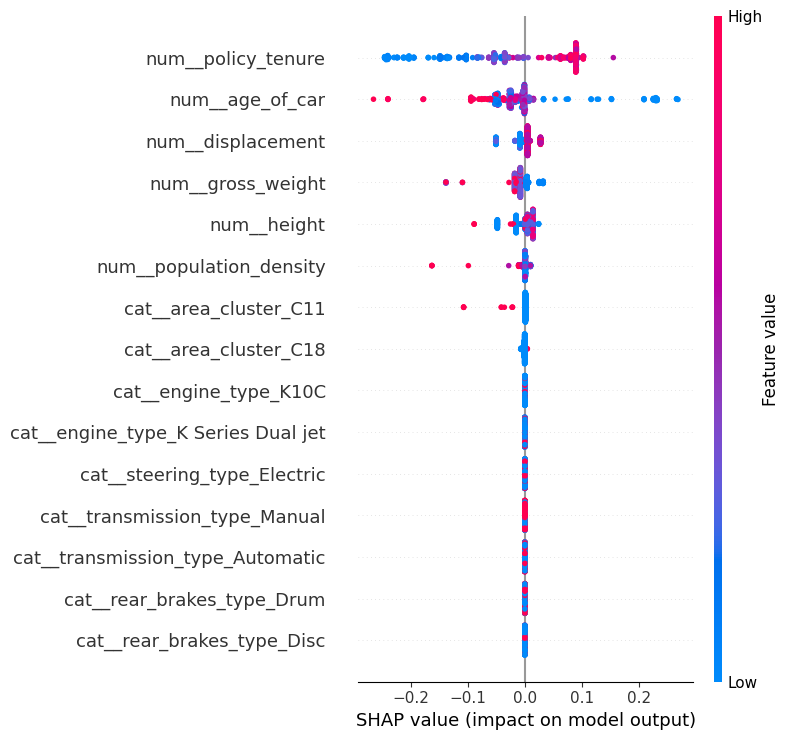

,feature,mean_abs_shap,mean_signed_shap,direction
0,num__policy_tenure,0.095270,-0.016866,Negative contribution on explainer output scale
1,num__age_of_car,0.041173,-0.006894,Negative contribution on explainer output scale
10,num__displacement,0.013653,-0.002904,Negative contribution on explainer output scale
13,num__gross_weight,0.013289,-0.007991,Negative contribution on explainer output scale
12,num__height,0.013257,-0.001450,Negative contribution on explainer output scale
3,num__population_density,0.002863,-0.001231,Negative contribution on explainer output scale
24,cat__area_cluster_C11,0.002402,-0.000052,Negative contribution on explainer output scale
31,cat__area_cluster_C18,0.000494,-0.000459,Negative contribution on explainer output scale
6,num__is_adjustable_steering,0.000000,0.000000,Negative contribution on explainer output scale
2,num__age_of_policyholder,0.000000,0.000000,Negative contribution on explainer output scale


Any retained Featuretools feature in top-10 SHAP features: False
Matching features: []


In [106]:
if shap_available:
    if isinstance(shap_values, list):
        positive_shap = shap_values[1] if len(shap_values) > 1 else shap_values[0]
    else:
        positive_shap = np.asarray(shap_values)
        if positive_shap.ndim == 3:
            positive_shap = positive_shap[:, :, 1]
    positive_shap = np.asarray(positive_shap)
    shap.summary_plot(positive_shap, explain_sample, max_display=15, show=False)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "shap_summary_automl.png", dpi=160, bbox_inches="tight")
    plt.show()
    shap_summary = pd.DataFrame({
        "feature": explain_sample.columns,
        "mean_abs_shap": np.abs(positive_shap).mean(axis=0),
        "mean_signed_shap": positive_shap.mean(axis=0)
    })
    shap_summary["direction"] = np.where(
        shap_summary["mean_signed_shap"] > 0,
        "Positive contribution on explainer output scale",
        "Negative contribution on explainer output scale"
    )
    shap_summary = shap_summary.sort_values("mean_abs_shap", ascending=False)
    shap_summary.to_csv(OUT_DIR / "shap_feature_summary_automl.csv", index=False)
    display(shap_summary.head(20))
    top_ten_features = set(shap_summary.head(10)["feature"])
    ft_in_top_ten = [feature for feature in featuretools_features if feature in top_ten_features]
    print("Any retained Featuretools feature in top-10 SHAP features:", bool(ft_in_top_ten))
    print("Matching features:", ft_in_top_ten)

## 11. AutoML predictions and comparison with Notebook 2

In [107]:
def assign_risk_levels(probabilities):
    q40, q75, q90 = np.quantile(probabilities, [0.40, 0.75, 0.90])
    levels = np.select(
        [probabilities <= q40, probabilities <= q75, probabilities <= q90],
        ["Low", "Medium", "High"], default="Very High"
    )
    return levels, {"q40": float(q40), "q75": float(q75), "q90": float(q90)}

risk_levels, risk_cut_points = assign_risk_levels(chosen_probability)
prediction_output = pd.DataFrame({
    "policy_id": policy_ids.loc[X_test.index].values,
    "actual_outcome": y_test.values,
    "predicted_class": chosen_prediction,
    "claim_probability": chosen_probability,
    "risk_level": risk_levels
})
prediction_output.to_csv(OUT_DIR / "prediction_output.csv", index=False)
print("Risk cut points:", risk_cut_points)

Risk cut points: {'q40': 0.4757586666204691, 'q75': 0.6025659049892819, 'q90': 0.6025659049892819}


In [108]:
from pathlib import Path
import pandas as pd

csv_path = Path("/content/prediction_output.csv")

if csv_path.exists():
    stage2_predictions = pd.read_csv(csv_path)

    print("CSV loaded successfully!")
    print("Shape:", stage2_predictions.shape)
    print("Columns:", stage2_predictions.columns.tolist())

    print("\nNotebook 2 risk-band distribution:")
    display(
        stage2_predictions["risk_level"]
        .value_counts(normalize=True)
        .reindex(risk_order, fill_value=0)
    )

    print("\nNotebook 3 risk-band distribution:")
    display(
        prediction_output["risk_level"]
        .value_counts(normalize=True)
        .reindex(risk_order, fill_value=0)
    )
else:
    print("CSV not found. Upload prediction_output.csv.")

CSV loaded successfully!
Shape: (11719, 5)
Columns: ['policy_id', 'actual_outcome', 'predicted_class', 'claim_probability', 'risk_level']

Notebook 2 risk-band distribution:


,proportion
risk_level,
Low,0.481696
Medium,0.453366
High,0.000000
Very High,0.064937



Notebook 3 risk-band distribution:


,proportion
risk_level,
Low,0.481696
Medium,0.453366
High,0.000000
Very High,0.064937


In [109]:
print("Claim probability summary:")
display(prediction_output["claim_probability"].describe())

print("\nRisk-band definitions:")
display(
    prediction_output.groupby("risk_level", observed=False)
    ["claim_probability"]
    .agg(["count", "min", "max", "mean"])
)

Claim probability summary:


,claim_probability
count,11719.000000
mean,0.465950
std,0.147095
min,0.073677
25%,0.334912
50%,0.485984
75%,0.602566
max,0.956431



Risk-band definitions:


,count,min,max,mean
risk_level,,,,
Low,5645,0.073677,0.475759,0.338651
Medium,5313,0.485984,0.602566,0.569499
Very High,761,0.614270,0.956431,0.687295


### Interpretation: AutoML risk bands and comparison with Notebook 2

The AutoML pipeline uses the same 40th / 75th / 90th percentile rule. The cut points are identical to Notebook 2 (q40 = 0.4758, q75 = q90 = 0.6026), so the **High band is again empty**. Its claim rate is undefined, not zero. Counts are Low 5,645, Medium 5,313, High 0, Very High 761 (total 11,719).

The risk-band distribution matches Notebook 2 exactly. This is expected: no Featuretools features were retained (0 of 462 candidates passed the correlation filter), so the "extended" decision tree uses the same 30 base features, and its test metrics are identical to Notebook 2's tuned tree. The AutoML pipeline therefore **did not change the risk segmentation**. The Notebook 2 comparison file was read from disk, so this comparison confirms consistency but is not an independent test of a different model.

As in Notebook 2, observed claim rates can be called monotonic only across the three populated bands. Cut points were not changed to fill the High band.

## 12. Business KPIs and dashboard source data
Full-dataset descriptive KPIs use all available raw policy rows. Risk-band counts are based only on the held-out test policies scored by this model.

In [110]:
raw_path = Path("/content/dataset.csv")
raw_df = pd.read_csv(raw_path)

scored_df = raw_df.merge(
    prediction_output[["policy_id", "claim_probability", "risk_level"]],
    on="policy_id",
    how="left",
    validate="one_to_one"
)

total_policies = int(len(raw_df))
total_claims = int(raw_df["is_claim"].sum())
claim_rate = float(raw_df["is_claim"].mean())
high_risk_count = int(scored_df["risk_level"].isin(["High", "Very High"]).sum())
average_ncap = float(raw_df["ncap_rating"].mean())

kpis = {
    "total_policies": total_policies,
    "total_claims": total_claims,
    "claim_rate": claim_rate,
    "high_risk_customers_scored_test_only": high_risk_count,
    "average_ncap_rating": average_ncap,
    "scored_test_policies": int(scored_df["risk_level"].notna().sum())
}

print(json.dumps(kpis, indent=2))
(OUT_DIR / "business_kpis.json").write_text(json.dumps(kpis, indent=2))
scored_df.to_csv(OUT_DIR / "scored_policy_merge.csv", index=False)

print("Business KPIs and scored policy file saved successfully.")

{
  "total_policies": 58592,
  "total_claims": 3748,
  "claim_rate": 0.06396777717094485,
  "high_risk_customers_scored_test_only": 761,
  "average_ncap_rating": 1.7599501638448936,
  "scored_test_policies": 11719
}
Business KPIs and scored policy file saved successfully.


### Interpretation and limitations
- The full-dataset claim count, claim rate and mean NCAP rating are descriptive values. The high-risk count is limited to held-out test policies that received model-generated risk levels.
- A top-ten SHAP feature is an explanation of model behavior, not proof of causal impact.